# Coupling attitude to a real relative trajectory

Every attitude notebook so far has pointed at a fixed target, chosen once, or recovered an attitude from measurements taken in isolation. This notebook ties attitude to the relative motion the rest of this project actually designs: as the deputy flies the same far-range hop built in `cw_fundamentals.ipynb` (a 5 km hold point onto the 2:1 safety ellipse's far point), it keeps a body axis pointed at the chief the whole time, re-pointing periodically as the relative geometry evolves rather than chasing a single closed-form target.

The target direction is recomputed every `retarget_interval` seconds from wherever the deputy actually is at that instant, using `triad_attitude`, the same two-vector construction from the determination notebook, applied here to *design* an attitude rather than *recover* one from measurements. Between updates, the target is held fixed and the PD controller from `attitude_pointing_control.ipynb` chases it, exactly the way a real spacecraft tracks periodically updated guidance commands rather than a continuously recomputed closed form.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.dynamics.relative.cw import cw_targeting
from ios_mission_planner.dynamics.relative.relative_orbit import RelativeOrbit, state_from_relative_orbit
from ios_mission_planner.dynamics.attitude.target_pointing import (
    target_quaternion_toward_chief, fly_with_periodic_retargeting,
)

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

## The hop, and a starting attitude already pointed correctly

Same far-range hop as `cw_fundamentals.ipynb`: a 5 km hold point, a 0.75-orbit transfer onto the 2:1 ellipse's far point. The deputy starts with zero body rate and an attitude already pointed exactly at the chief from the hold point, so any pointing error that appears afterward is purely from the geometry changing faster than the retargeting keeps up with, not from an initial transient.

In [2]:
n = 0.0011  # chief mean motion [rad/s]
period = 2 * np.pi / n

r0, v0 = np.array([0.0, -5000.0, 0.0]), np.zeros(3)
orbit_far = RelativeOrbit(x_off=0.0, y_c=0.0, rho=200.0, alpha=np.pi / 2)
state_far = state_from_relative_orbit(orbit_far, n)
hop_duration = 0.75 * period

dv1, dv2 = cw_targeting(r0, v0, state_far[:3], state_far[3:], hop_duration, n)
relative_state0 = np.concatenate([r0, v0 + dv1])

q0 = target_quaternion_toward_chief(relative_state0[:3])
attitude_state0 = np.concatenate([q0, [0.0, 0.0, 0.0]])

inertia = (10.0, 15.0, 20.0)
kp, kd = 2.0, 8.0

t, rel, att, pointing_error = fly_with_periodic_retargeting(
    relative_state0, attitude_state0, n, inertia, kp, kd,
    total_duration=hop_duration, retarget_interval=30.0, pts_per_interval=30,
)

print(f"hop duration: {hop_duration/60:.1f} min, retargeting every 30 s "
      f"({int(np.ceil(hop_duration/30.0))} updates)")
print(f"max pointing error: {pointing_error.max():.2f} deg, mean: {pointing_error.mean():.3f} deg")

hop duration: 71.4 min, retargeting every 30 s (143 updates)
max pointing error: 2.39 deg, mean: 0.405 deg


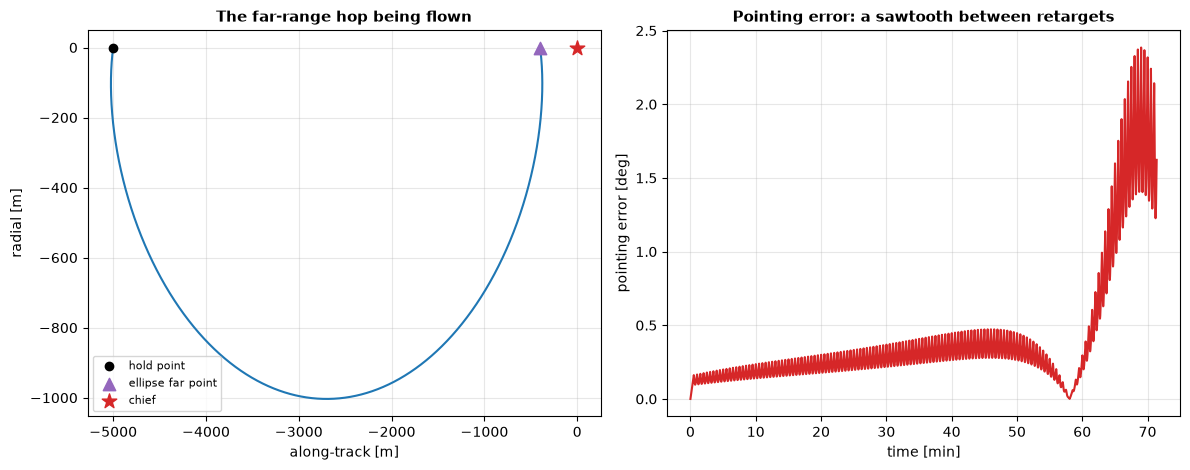

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].plot(rel[:, 1], rel[:, 0], color=COL_ANA, lw=1.5)
axes[0].scatter([rel[0, 1]], [rel[0, 0]], color="k", zorder=5, label="hold point")
axes[0].scatter([rel[-1, 1]], [rel[-1, 0]], color=COL_ZONE, marker="^", s=80, zorder=5, label="ellipse far point")
axes[0].scatter([0], [0], color=COL_NUM, marker="*", s=120, zorder=5, label="chief")
axes[0].set_xlabel("along-track [m]"); axes[0].set_ylabel("radial [m]")
axes[0].set_title("The far-range hop being flown")
axes[0].legend(fontsize=8)

axes[1].plot(t / 60.0, pointing_error, color=COL_NUM)
axes[1].set_xlabel("time [min]"); axes[1].set_ylabel("pointing error [deg]")
axes[1].set_title("Pointing error: a sawtooth between retargets")

fig.tight_layout()
fig.savefig("attitude_coupled_hop_pointing.png", dpi=140)

The sawtooth is the signature of periodic retargeting: error grows as the relative geometry drifts away from the last commanded target, then drops sharply the instant a new target arrives and the controller snaps toward it. It never grows without bound, the same qualitative behavior the recursive filter notebook showed for dead reckoning versus a corrected estimate, except here it is the *target* going briefly stale rather than the estimate drifting.

The sawtooth's amplitude itself is not constant either, and that pattern is worth reading rather than averaging away: it grows noticeably larger in the last few minutes, right as the deputy closes in on the ellipse far point. The direction to the chief sweeps through a wider angle per unit time at short range than at long range, for the same reason a nearby lamppost appears to swing past faster than a distant one as you walk by it, so the same fixed retargeting cadence falls further behind exactly when it matters most, during the closing phase of an approach.

## How much the retargeting cadence matters

A shorter interval should track the changing geometry more tightly, at the cost of recomputing (and commanding) the target more often. Sweeping the interval shows exactly that trade-off, directly, on this same hop.

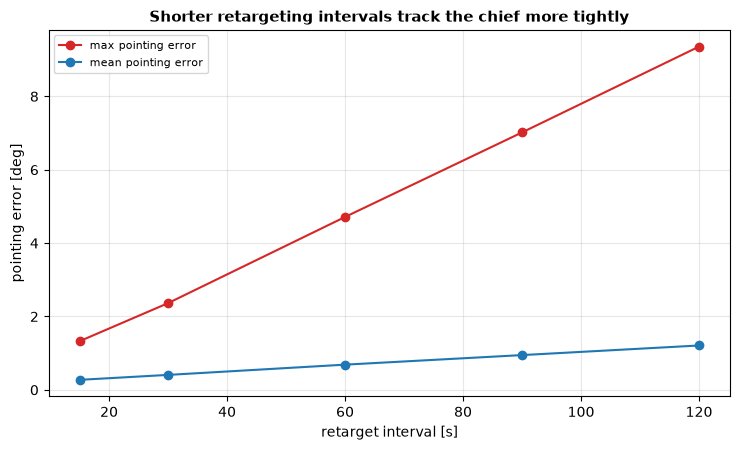

In [4]:
intervals = np.array([120.0, 90.0, 60.0, 30.0, 15.0])
max_errors, mean_errors = [], []

for interval in intervals:
    _, _, _, err = fly_with_periodic_retargeting(
        relative_state0, attitude_state0, n, inertia, kp, kd,
        total_duration=hop_duration, retarget_interval=interval, pts_per_interval=20,
    )
    max_errors.append(err.max())
    mean_errors.append(err.mean())

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(intervals, max_errors, "o-", color=COL_NUM, label="max pointing error")
ax.plot(intervals, mean_errors, "o-", color=COL_ANA, label="mean pointing error")
ax.set_xlabel("retarget interval [s]")
ax.set_ylabel("pointing error [deg]")
ax.set_title("Shorter retargeting intervals track the chief more tightly")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("attitude_retarget_interval_sweep.png", dpi=140)

Both the worst-case and the average pointing error fall steadily as the retargeting cadence tightens, exactly what a periodic-update scheme should do: there is no magic interval that is simultaneously free and perfect, only a trade between how often guidance gets recomputed and how far the attitude is allowed to lag behind the real geometry.

## Summary

`target_quaternion_toward_chief` and `fly_with_periodic_retargeting` couple this chapter's attitude dynamics to the relative motion built everywhere else in this project: a body axis tracks the chief through a real flown trajectory, not a fixed inertial direction chosen once, with the tracking error directly, quantitatively tied to how often the target gets recomputed. `boresight_pointing_error_deg` is the piece worth noting for the safety chapter specifically: it checks whether a sensor would actually have the chief in view given the attitude the controller really achieves, a genuinely different question from the approach corridor's purely geometric check on the trajectory alone.

This is still a deliberately bounded coupling, not a full 6-degree-of-freedom mission simulation. The target is still computed in the chief's LVLH frame treated as if it were inertial, a stated simplification rather than a true inertial-frame composition; the relative dynamics are still the linearized, circular-chief Hill equations from the relative dynamics chapter, not the eccentric-chief or J2-aware models built elsewhere in this project; and nothing here feeds a pointing requirement back into how the trajectory itself is designed, only checks how well a fixed trajectory's attitude requirement is met. Any of those would be a reasonable next extension, not something this notebook attempts.